**Python DA Assignment 2 - Data Visualization**

**1) Loading the Taxis Dataset**

In [3]:
import seaborn as sns
df=sns.load_dataset("taxis")
df.head()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


In [3]:
df.shape

(6433, 14)

In [5]:
df.columns

Index(['pickup', 'dropoff', 'passengers', 'distance', 'fare', 'tip', 'tolls',
       'total', 'color', 'payment', 'pickup_zone', 'dropoff_zone',
       'pickup_borough', 'dropoff_borough'],
      dtype='str')

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6433 entries, 0 to 6432
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   pickup           6433 non-null   datetime64[us]
 1   dropoff          6433 non-null   datetime64[us]
 2   passengers       6433 non-null   int64         
 3   distance         6433 non-null   float64       
 4   fare             6433 non-null   float64       
 5   tip              6433 non-null   float64       
 6   tolls            6433 non-null   float64       
 7   total            6433 non-null   float64       
 8   color            6433 non-null   str           
 9   payment          6389 non-null   str           
 10  pickup_zone      6407 non-null   str           
 11  dropoff_zone     6388 non-null   str           
 12  pickup_borough   6407 non-null   str           
 13  dropoff_borough  6388 non-null   str           
dtypes: datetime64[us](2), float64(5), int64(1), str(6)


**Explanation**
* import seaborn as sns -->imported seaborn library.
* taxis is built-in dataset in seaborn- it's a New York taxi rides data.
* df.head()shows first 5 rows to see what data look like.
* for checking size: df.shape(), (6433,14)--> 6433 rows= 6433 taxi rides & 14 columns= 14 details for each ride.
* checking columns: df.columns--> just lists all 14 column names.
* checking info: df.info()--> shows data type and having any missing values.

**2) Handling Missing Values**

In [7]:
df.isnull().sum()

pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

**Explanation**
* df.isnull().sum()--> counts empty values in each column.
* Output shows- 9 columns have 0 missing and
* payment            44
* pickup_zone        26
* dropoff_zone       45
* pickup_borough     26
* dropoff_borough    45

In [4]:
df["payment"]=df["payment"].fillna(df["payment"].mode()[0])
df["pickup_zone"]=df["pickup_zone"].fillna(df["pickup_zone"].mode()[0])
df["dropoff_zone"]=df["dropoff_zone"].fillna(df["dropoff_zone"].mode()[0])
df["pickup_borough"]=df["pickup_borough"].fillna(df["pickup_borough"].mode()[0])
df["dropoff_borough"]=df["dropoff_borough"].fillna(df["dropoff_borough"].mode()[0])

In [3]:
df.isnull().sum()

pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64

**Explanation**
* df["payment"].fillna(df["payment"].mode()[0]) means fill empty places with the most common value and same code is used to solve the missing values in case of pickup_zone, dropoff_zone, pickup_borough, dropoff_borough. Here mode() is used because missing values are in categorical columns.
* df.isnull().sum()--> to check again the missing if any. Output is with 0 for all. So the data is now cleaned and perfect for making charts. 

**3) Visualizations using Matplotlib/Pandas Plot:**

**Line Chart**  
* Plot a line chart to visualize the fare over time, using the pickup timestamp as the 
x-axis and fare as the y-axis. Ensure the pickup column is converted to a datetime 
format before plotting.

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

In [5]:
df["pickup"]=pd.to_datetime(df["pickup"])

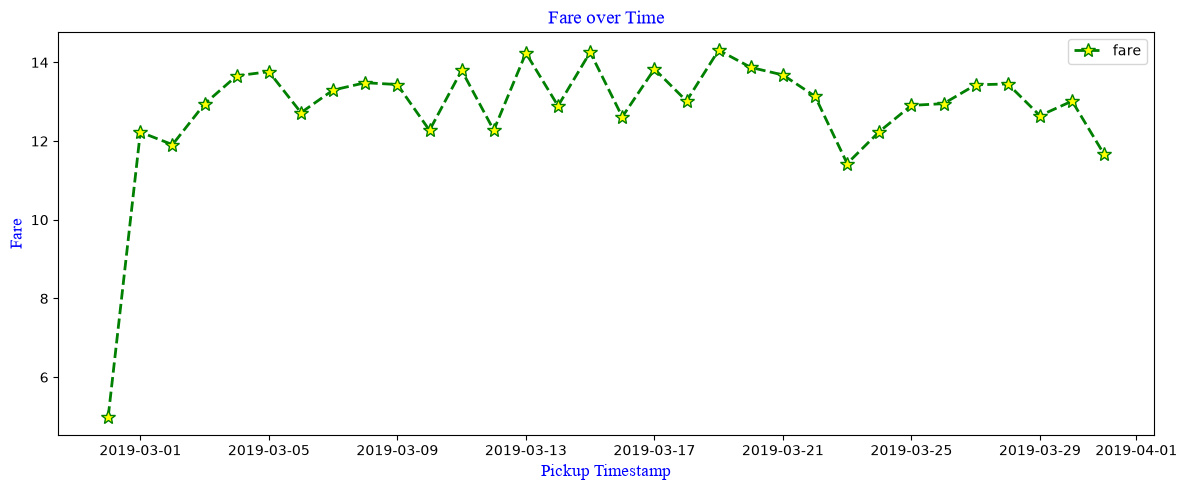

In [103]:
df_sort=df.sort_values("pickup")
daily=df_sort.groupby(df_sort["pickup"].dt.date)["fare"].mean()
plt.figure(figsize=(12,5))
plt.plot(daily.index,daily.values,color="green",marker="*",markerfacecolor="yellow",markersize=10,linewidth=2,label="fare",linestyle="--")
plt.title("Fare over Time",color="blue",font="Times New Roman",size=14)
plt.xlabel("Pickup Timestamp",color="blue",font="Times New Roman",size=12)
plt.ylabel("Fare",color="blue",font="Times New Roman",size=12)
plt.tight_layout()
plt.legend()
plt.show()

**Explanation**
* df.sort_values("pickup") - Sort data from oldest to newest date.
* groupby(df_sort["pickup"].dt.date)["fare"].mean() - Group by each day and calculate daily average fare. This is to avoid too many points in graph.
* plt.plot(...) - Draw line chart. X = daily date, Y = daily average fare. Green dashed line, yellow star marker.

**Analysis Findings**
* On 2019-02-28 / 03-01 fare is very low 5 dollars, then jumps to 12 dollars - starting point.
* After that fare is mostly stable between 12 to 14 dollars.
* Graph goes up and down daily - fare is fluctuating but no big increase or decrease trend.
* Overall trend is flat - average fare is consistent over the month.

**Bar Chart** 
* Create a bar chart to show the total fare for each pickup_borough. Group the data 
by pickup_borough and sum the fare for each group.

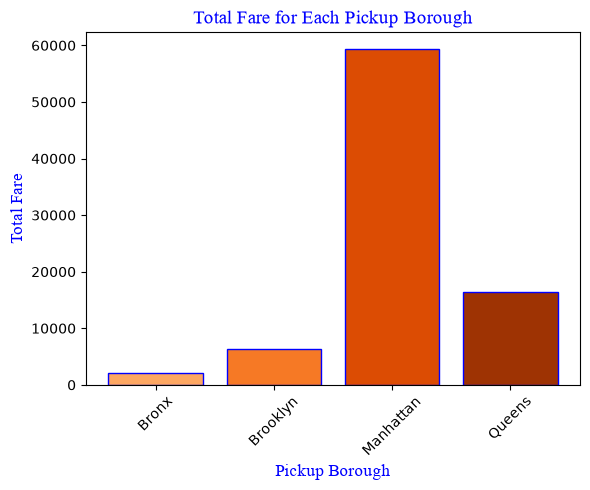

In [8]:
import numpy as np
total_fare = df.groupby('pickup_borough')['fare'].sum()
x = total_fare.index
y = total_fare.values

plt.figure(figsize=(6,5))
cmap=plt.cm.Oranges
plt.bar(x,y,color=cmap(np.linspace(0.4,0.9,len(x))),edgecolor="b")
plt.title("Total Fare for Each Pickup Borough",color="b",font="Times New Roman",fontsize=14)
plt.xlabel("Pickup Borough",color="b",font="Times New Roman",fontsize=12)
plt.ylabel("Total Fare",color="b",font="Times New Roman",fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Explanation**
* df.groupby('pickup_borough')['fare'].sum() - Groups data by borough (Bronx, Brooklyn, Manhattan, Queens) and sums total fare for each group.
* x-axis is borough names and y-axis is total fare amount.
* plt.bar(x,y, color=cmap...) - Draws bar chart. Oranges colormap gives different orange shades, edgecolor="b" gives blue border.
* rotation=45 - Rotates borough names so they don't overlap.

**Analysis Findings**
* Manhattan is highest - 58,000 total fare. Means most taxi pickups / highest earning area.
* Queens is second, Brooklyn is third, Bronx is lowest.
* Manhattan dominates taxi business - almost 75% of total fare comes from Manhattan.

**Pie Chart**  
* Plot a pie chart showing the distribution of trips based on the payment method (credit 
card, cash, etc.). Each slice should represent the count of trips for a specific payment 
method. 

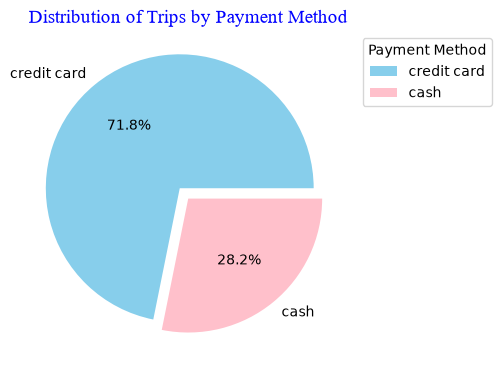

In [66]:
payment_counts=df['payment'].value_counts()
labels = payment_counts.index
sizes =payment_counts.values
plt.figure(figsize=(5,5))
plt.pie(sizes,labels=labels,autopct='%1.1f%%',colors=["skyblue","pink"],explode=(0.1,0))
plt.title("Distribution of Trips by Payment Method", color="b",font="Times New Roman",fontsize=14)
plt.legend(title="Payment Method",bbox_to_anchor=(1,1),loc="upper left")
plt.tight_layout()
plt.show()

**Explanation**
* df['payment'].value_counts() - Counts how many times each payment method appears.
* labels = index - Labels are payment names (credit card, cash)
* sizes = values - Sizes are their counts
* plt.pie(...) - Draws pie chart. autopct='%1.1f%%' shows percentage on chart, colors=["skyblue","pink"] sets colors, explode=(0.1,0) pulls credit card slice slightly out to highlight.

**Analysis Findings**
* Credit card - 71.8% - Skyblue slice, majority of trips.
* Cash - 28.2% - Pink slice, minority.
* Most passengers prefer to pay by credit card over cash. Credit card is used almost 2.5 times more than cash.

**Histogram** 
* Create a histogram to visualize the distribution of distance. Customize the number of 
bins for better granularity and ensure the plot is easy to interpret.

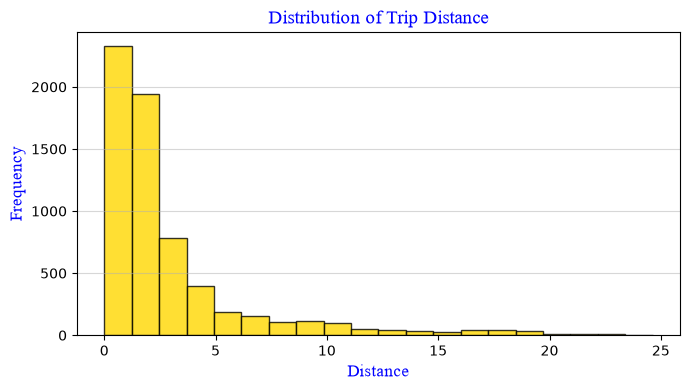

In [79]:
plt.figure(figsize=(7,4))
distance_data=df['distance'][df['distance']<25]
plt.hist(distance_data,bins=20,color="gold",edgecolor="black",alpha=0.8)
plt.title("Distribution of Trip Distance",color="b",font="Times New Roman",fontsize=14)
plt.xlabel("Distance",font="Times New Roman",fontsize=12,color="b")
plt.ylabel("Frequency",font="Times New Roman",fontsize=12,color="b")
plt.grid(axis='y',alpha=0.5)
plt.tight_layout()
plt.show()

**Explanation**
* df['distance'][df['distance']<25] - Takes distance column and keeps only trips less than 25 miles to remove outliers.
* plt.hist(..., bins=20, ...) - Makes histogram with 20 bars. color="gold" for bar color, edgecolor="black" for border, alpha=0.8 for transparency.
* plt.grid(axis='y') - Shows horizontal grid lines for easy reading.

**Analysis Findings**
* Most trips are very short - Highest bar is 0-2 miles with 2300 trips.
* Second highest - 1.5 to 3 miles with 1900 trips.
* After 3 miles, frequency drops sharply.
* Trips above 10 miles are very rare.
* This is a right-skewed graph. Most taxi trips in NYC are short trips (under 3 miles). People use taxis for short distances, long trips are uncommon.

**Box Plot**  
* Plot a box plot to visualize the distribution of tip amounts for each pickup_borough. 
Use pickup_borough as the categorical axis and tip as the numeric axis.

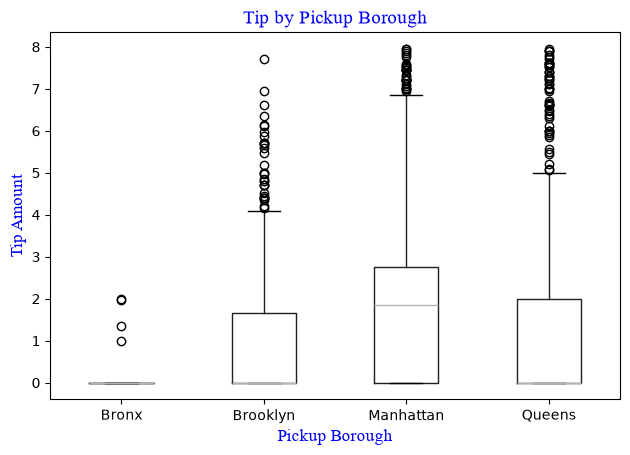

In [105]:
df[df['tip']<8].boxplot(column='tip',by='pickup_borough')
plt.title("Tip by Pickup Borough",font="Times New Roman",fontsize=14,color="b")
plt.suptitle("")
plt.xlabel("Pickup Borough",font="Times New Roman",fontsize=12,color="b")
plt.ylabel("Tip Amount",font="Times New Roman",fontsize=12,color="b")
plt.grid(False)
plt.tight_layout()
plt.show()

**Explanation**
* df[df['tip']<8].boxplot(column='tip', by='pickup_borough') - Draws box plot for tip. Only tips less than $8 are taken to remove big outliers. column='tip' is Y-axis, by='pickup_borough' groups by borough on X-axis.
* plt.title, xlabel, ylabel - Adds titles.
* plt.grid(False) - Removes grid.

**Analysis Findings**
* Bronx: Almost all tips are 0. Median is 0. Very low tips, only 3 outliers.
* Brooklyn: Median 0. Most tips between 0 to 1.7. Outliers up to 7.6.
* Manhattan: Highest tips. Median 1.8-1.9. Box is higher. Many tips up to 6.7 and lots of outliers near 8.
* Queens: Median 0. Box 0 to 2. Outliers from 5 upwards.
* Manhattan passengers give highest tips, followed by Queens and Brooklyn.
* Tip distribution has many outliers - some people give high tips in all boroughs.

**Visualizations using Seaborn:**

**Count Plot** 
* Create a count plot to visualize the number of trips in each pickup_borough. The 
x-axis should represent the boroughs, and the y-axis should show the count of trips. 

In [2]:
import seaborn as sns
import matplotlib.pyplot as plt

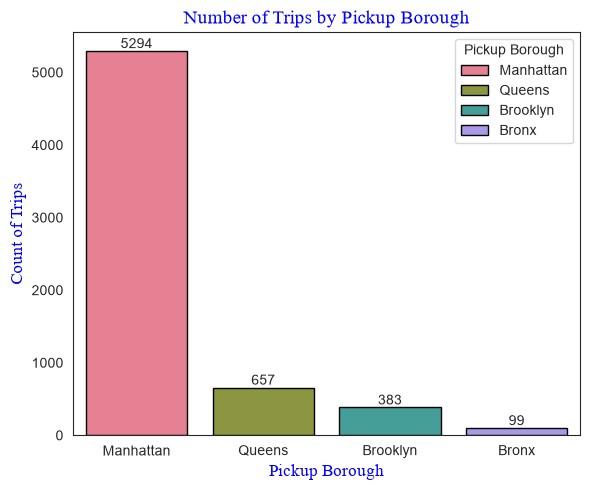

In [75]:
sns.set_style("white")
plt.figure(figsize=(6,5))
order=df['pickup_borough'].value_counts().index
ax=sns.countplot(x='pickup_borough',data=df,hue='pickup_borough',palette='husl',order=order,hue_order=order,edgecolor='black')

for container in ax.containers:
    ax.bar_label(container,fontsize=10)
plt.title("Number of Trips by Pickup Borough",color="b",font="Times New Roman",fontsize=14)
plt.xlabel("Pickup Borough",color="b",font="Times New Roman",fontsize=12)
plt.ylabel("Count of Trips",color="b",font="Times New Roman",fontsize=12)
plt.grid(False)
plt.legend(order,title="Pickup Borough")
plt.tight_layout()
plt.show()

**Explanation**
* sns.set_style("white") - Sets background style.
* order = df['pickup_borough'].value_counts().index - Orders boroughs by most trips to least trips.
* sns.countplot(x='pickup_borough', data=df, ...) - Seaborn count plot. X = borough, Y = automatically counts number of rows for each borough. palette='husl' gives different colors, hue='pickup_borough' for color legend.
* ax.bar_label(...) - Shows the count number on top of each bar.

**Analysis Findings**
* Manhattan - 5294 trips - Tallest bar, almost 82% of all trips.
* Queens - 657 trips.
* Brooklyn - 383 trips.
* Bronx - 99 trips - Lowest.
* Most demand is concentrated in Manhattan, very low demand in Bronx.

**Scatter Plot** 
* Plot a scatter plot to show the relationship between distance and fare. Use 
distance on the x-axis and fare on the y-axis to visualize any correlation. Color the 
points based on the pickup_borough to differentiate the trips by their respective 
boroughs. 

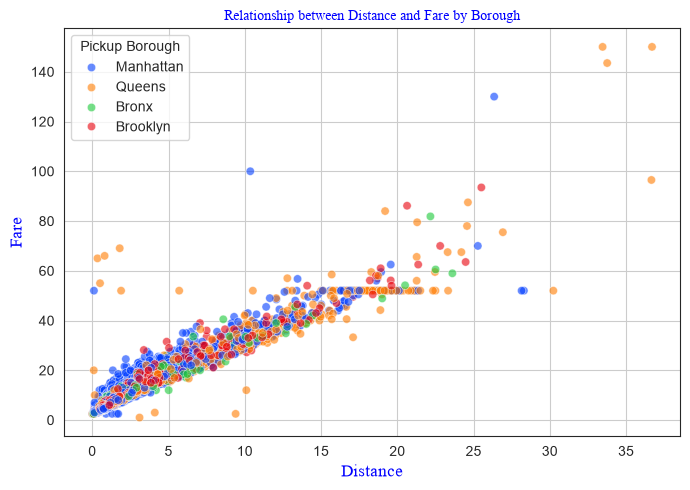

In [77]:
plt.figure(figsize=(7,5))
df_clean=df[(df['distance']>0) & (df['fare']>0) & (df['fare']<200)]
sns.scatterplot(data=df_clean,x='distance',y='fare',hue='pickup_borough',palette='bright',alpha=0.6)
plt.title("Relationship between Distance and Fare by Borough",color="b",fontsize=16,font="Times New Roman")
plt.xlabel("Distance",color="b",fontsize=12,font="Times New Roman")
plt.ylabel("Fare",color="b",fontsize=12,font="Times New Roman")
plt.legend(title="Pickup Borough")
plt.grid(True)
plt.tight_layout()
plt.show()

**Explanation**
* df_clean = df[(df['distance']>0) & (df['fare']>0) & (df['fare']<200)] - Cleaning step. Keeps only valid trips where distance > 0, fare > 0, and fare < 200 to remove errors and big outliers.
* sns.scatterplot(x='distance', y='fare', hue='pickup_borough') - Draws scatter plot. Each dot is one trip. X = distance, Y = fare. Color = borough. palette='bright' for colors, alpha=0.6 for transparency.

**Analysis Findings**
* Positive Correlation: As distance increases, fare increases. Dots form a clear upward line from bottom-left to top-right.
* Most trips: Clustered at 0-10 miles and 0-40 fare - mostly Manhattan (blue).
* Long trips: Above 25 miles, mostly Queens (orange).
* Fare is directly proportional to distance. Longer distance = higher fare & trips are mostly from Queens and Manhattan.

**Heatmap**  
* Plot a heatmap to visualize the correlation between numerical variables such as 
distance, fare, tip, tolls, and total. Use a correlation matrix to highlight the 
relationships.

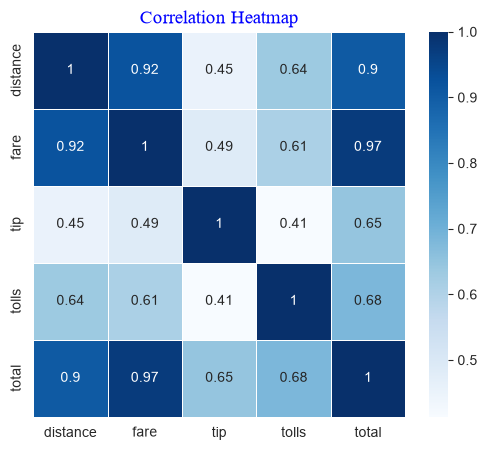

In [61]:
corr=df[['distance','fare','tip','tolls','total']].corr()
plt.figure(figsize=(6,5))
sns.heatmap(corr,annot=True,cmap='Blues',linewidths=0.5)
plt.title("Correlation Heatmap",color="b",font="Times New Roman",fontsize=14)
plt.show()

**Explanation**
* corr = df[['distance','fare','tip','tolls','total']].corr() - Calculates correlation matrix. Correlation shows how strongly 2 variables move together. Value is -1 to 1. 1 = perfect positive, 0 = no relation.
* sns.heatmap(corr, annot=True, cmap="Blues", linewidths=0.5) - Draws heatmap. annot=True shows numbers inside boxes. cmap="Blues" blue color shades - darker blue = higher correlation.

**Analysis Findings**
* Darkest blue = 1.0 (strongest), Lightest = 0.4 (weakest)
* fare and total - 0.97 - Very high. Total fare depends mostly on base fare. Expected.
* distance and fare - 0.92 - Very high. Longer distance = higher fare.
* distance and total - 0.90 - Very high. Longer distance = higher total bill.
* tip and tolls - 0.41 - Lowest correlation. Tips don't depend on tolls.
* tip with others - 0.45 to 0.65 - Moderate/low correlation. Tip is less connected to distance/fare.
* Fare is highly correlated with distance and total. If distance increases, fare and total increase. Tip is least correlated with other variables - people give tips independently of distance.

**Pair Plot** 
* Create a pair plot to visualize the pairwise relationships between distance, fare, tip, 
and total. Color the data points according to the pickup_zone method to compare 
how different zones affect these variables.

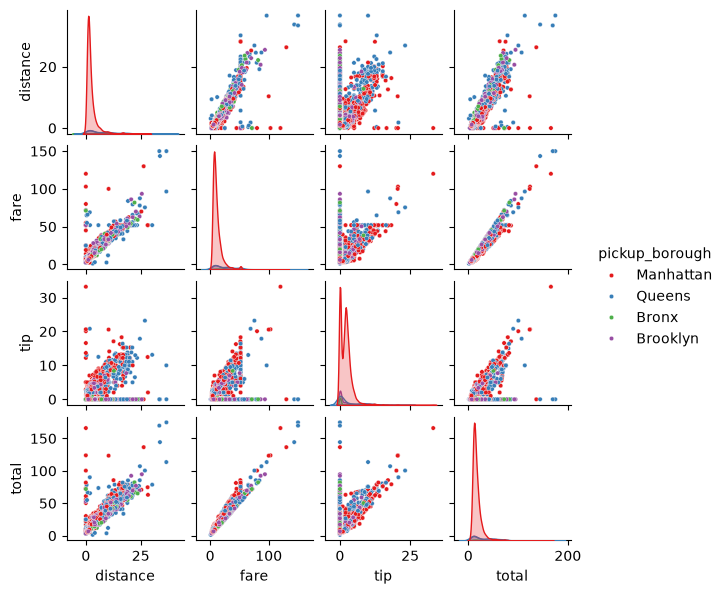

In [7]:
sns.pairplot(df[['distance','fare','tip','total','pickup_borough']],hue='pickup_borough',height=1.5,palette='Set1',diag_kind='kde',plot_kws={'s':10})
plt.show()

**Explanation**
* sns.pairplot(df[['distance','fare','tip','total','pickup_borough']], hue='pickup_borough', ...) - Pair plot draws every variable vs every other variable in a grid.
* hue='pickup_borough' - Colors dots by borough. Red=Manhattan, Blue=Queens from Set1 palette.
* height=1.5 - Size of each small plot.
* diag_kind='kde' - Diagonal shows density curve (how data is distributed) not histogram. High peak = many trips at that value.
* plot_kws={'s':10} - Dot size 10.

**Analysis Findings**
* distance vs fare / fare vs total / distance vs total - Strong straight line going up. Positive correlation. Fare increases when distance increases, total increases when fare increases.
* distance vs tip / fare vs tip - Dots scattered, no clear line. Weak correlation. Tips are random 0-20, not strongly dependent on distance/fare.
* Borough effect: Manhattan (red) dominates all plots because 5294 points are Manhattan. Pattern is same for all boroughs - no separate cluster. Means relationship between fare/distance is similar in all boroughs.
* distance, fare, total are strongly linked. Tip is weakly linked. Borough color does not create separate groups, relationship is same across NYC.

**Violin Plot**  
* Plot a violin plot to show the distribution of fare for each payment method. Use the 
payment method as the categorical axis and fare as the numeric axis to visualize its 
distribution.

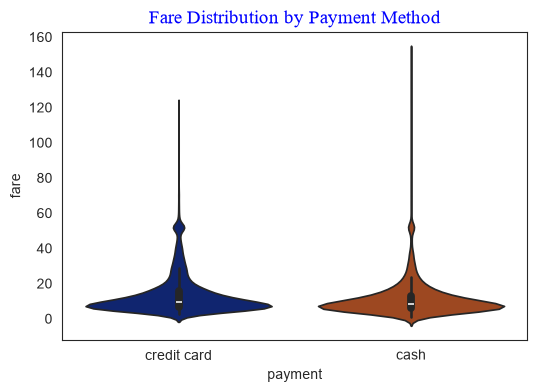

In [74]:
plt.figure(figsize=(6,4))
sns.violinplot(x='payment',y='fare',data=df,hue='payment',palette='dark')
plt.title("Fare Distribution by Payment Method",color="b",font="Times New Roman",fontsize=14)
plt.show()

**Explanation**
* sns.violinplot(x='payment', y='fare', data=df, hue='payment', palette='dark') - Violin plot. X = payment type (credit card, cash), Y = fare. Violin shape shows distribution - wider = more trips at that fare. hue='payment' gives different color to each. palette='dark' dark colors.
* Inside violin you see a small box plot - white dot = median, black box = 25% to 75% data.

**Analysis Findings**
* Both look almost same: Both violins are very fat at bottom around 8-12 fare. Means most trips, whether paid by card or cash, have low fare.
* Long thin tail on top: Both go up to 120-155. Very few high-fare trips for both methods. Credit card goes to 125, cash goes to 155.
* Small bump at 50: Both have a small bulge around 50 - some medium-distance trips like airport.
* Payment method does not affect fare distribution. People use both cash and credit card for similar types of trips. Most trips are low fare for both.